# CISC 473 — Laplace Redux (Last-Layer Laplace) ResNet-20 on CIFAR-10 + Split Conformal Prediction

Implements **Laplace approximations** following Daxberger et al., 2021,
*"Laplace Redux — Effortless Bayesian Deep Learning"*
(https://arxiv.org/abs/2106.14806), using the authors' `laplace-torch` library
(`pip install laplace-torch`).

What changes vs. the baseline / MC Dropout notebooks:
- The network is the plain `cifar10_resnet20` model, trained
  exactly like the baseline.
  This gives the **MAP estimate** `theta_MAP`. Laplace is post-hoc and it does not
  change training at all.
- After training, a Gaussian posterior `N(theta_MAP, H^-1)` is fit over the
  **last layer only** (`subset_of_weights="last_layer"`, 650 params) using a
 generalized Gauss-Newton Hessian. The paper mentioned in the midterm report (Kristadi et al.) recommends last-layer Laplace as the cheap, strong default.
- The **prior precision** is tuned by maximizing the **marginal likelihood**
  (`method="marglik"`), which needs no held-out data, so the calibration split
  stays untouched for conformal prediction.
- Predictions use a GLM posterior with a probit
  approximation, which is anclosed-form, sampling-free predictive distribution.

Data loading, the 60/20/20 stratified split, training
hyperparameters, ECE/NLL definitions, and the split-conformal (APS) layer is
identical in structure to the MC Dropout notebook, so they are directly comparable.

In [1]:
import os
import json
import pickle
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from laplace import Laplace

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

D:\University\Fourth Year - 2026-2027\CISC 473\CISC-473-P23\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Using device: cuda


In [2]:
# ----------------------------- Config ---------------------------------------
DATA_DIR = Path("../data/cifar-10-batches-py")

SEEDS = [0]          # keep in sync with the baseline notebook for a fair split
EPOCHS = 40
BATCH_SIZE = 128
LR = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

TRAIN_FRAC = 0.6
TEST_FRAC = 0.2
CAL_FRAC = 0.2

ALPHA = 0.1          # miscoverage rate -> target 90% coverage
ECE_BINS = 15

# Laplace Redux settings (Daxberger et al. 2021)
LAPLACE_SUBSET = "last_layer"     # 'last_layer' | 'all' | 'subnetwork'
HESSIAN_STRUCTURE = "full"        # 'kron' (KFAC) | 'full' | 'diag', where 'full' is also cheap for 650 params
PRIOR_PREC_METHOD = "marglik"     # tune prior precision by marginal likelihood (no extra data needed, thus no calibration set needed for this)
PRED_TYPE = "glm"                 # linearized posterior
LINK_APPROX = "probit"            # closed-form softmax-Gaussian approximation

RESULTS_PATH = Path("laplace_resnet20_results.json")
MODEL_PATH = Path("../models/laplace_model/laplace_resnet20_seed0.pt")

CIFAR_MEAN = (0.4914, 0.4822, 0.4465) # Found from online resources, can also be calculated empirically
CIFAR_STD = (0.2470, 0.2435, 0.2616) # Likewise


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [3]:
def _unpickle(path):
    with open(path, "rb") as f:
        return pickle.load(f, encoding="bytes")


def load_cifar10(data_dir: Path):
    """Pools all 5 train batches + the test batch into 60,000 images, then
    re-split 60/20/20 below -- same pooling as the baseline / MC Dropout notebooks."""
    images, labels = [], []

    for i in range(1, 6):
        batch = _unpickle(data_dir / f"data_batch_{i}")
        images.append(batch[b"data"])
        labels.extend(batch[b"labels"])

    test_batch = _unpickle(data_dir / "test_batch")
    images.append(test_batch[b"data"])
    labels.extend(test_batch[b"labels"])

    images = np.concatenate(images, axis=0)
    images = images.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)  # NHWC, uint8
    labels = np.array(labels, dtype=np.int64)
    return images, labels


all_images, all_labels = load_cifar10(DATA_DIR)
print(f"Loaded {all_images.shape[0]} images, shape={all_images.shape[1:]}, "
      f"classes={np.unique(all_labels)}")

Loaded 60000 images, shape=(32, 32, 3), classes=[0 1 2 3 4 5 6 7 8 9]


In [4]:
# Stratified 60/20/20 split
def stratified_split(labels, fracs, seed):
    assert abs(sum(fracs) - 1.0) < 1e-6
    rng = np.random.RandomState(seed)
    split_idxs = [[] for _ in fracs]

    for c in np.unique(labels):
        c_idx = np.where(labels == c)[0]
        rng.shuffle(c_idx)
        n = len(c_idx)
        cuts = np.cumsum([int(round(n * f)) for f in fracs])
        cuts[-1] = n
        start = 0
        for i, end in enumerate(cuts):
            split_idxs[i].append(c_idx[start:end])
            start = end

    return [np.concatenate(idx) for idx in split_idxs]


train_idx, test_idx, cal_idx = stratified_split(
    all_labels, [TRAIN_FRAC, TEST_FRAC, CAL_FRAC], seed=SEEDS[0]
)
print(f"train={len(train_idx)}  test={len(test_idx)}  calibration={len(cal_idx)}")

train=36000  test=12000  calibration=12000


In [5]:
class CIFAR10Array(Dataset):
    def __init__(self, images, labels, indices, train: bool):
        self.images = images[indices]
        self.labels = labels[indices]
        self.train = train
        self.mean = np.array(CIFAR_MEAN, dtype=np.float32).reshape(3, 1, 1)
        self.std = np.array(CIFAR_STD, dtype=np.float32).reshape(3, 1, 1)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        img = self.images[i]

        if self.train:
            padded = np.pad(img, ((4, 4), (4, 4), (0, 0)), mode="reflect")
            top = np.random.randint(0, 9)
            left = np.random.randint(0, 9)
            img = padded[top:top + 32, left:left + 32, :]
            if np.random.rand() < 0.5:
                img = img[:, ::-1, :]

        img = img.astype(np.float32).transpose(2, 0, 1) / 255.0
        img = (img - self.mean) / self.std
        return torch.from_numpy(img.copy()), int(self.labels[i])


train_ds = CIFAR10Array(all_images, all_labels, train_idx, train=True)
# Same training images but WITHOUT augmentation -- used to fit the Laplace Hessian,
# so the posterior is computed on the clean data distribution.
train_noaug_ds = CIFAR10Array(all_images, all_labels, train_idx, train=False)
test_ds = CIFAR10Array(all_images, all_labels, test_idx, train=False)
cal_ds = CIFAR10Array(all_images, all_labels, cal_idx, train=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
train_noaug_loader = DataLoader(train_noaug_ds, batch_size=256, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=0)
cal_loader = DataLoader(cal_ds, batch_size=256, shuffle=False, num_workers=0)

## ResNet-20 (MAP training)

The unmodified `cifar10_resnet20` from `torch.hub`. Its last layer is `fc`
(64 -> 10), which is the layer `laplace-torch` will place the Gaussian posterior over.

In [6]:
def build_model():
    model = torch.hub.load("chenyaofo/pytorch-cifar-models", "cifar10_resnet20", pretrained=False)
    return model.to(DEVICE)


model = build_model()
print(f"Total parameters: {sum(p.numel() for p in model.parameters())}")
print(f"Last-layer parameters: {sum(p.numel() for p in model.fc.parameters())}")

Using cache found in C:\Users\edwar/.cache\torch\hub\chenyaofo_pytorch-cifar-models_master


Total parameters: 272474
Last-layer parameters: 650


## Training the MAP Baseline

In [7]:
# Training the MAP baseline
def evaluate_loss_acc(model, loader):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)
    return loss_sum / total, correct / total


def train_baseline(seed):
    set_seed(seed)
    model = build_model()
    optimizer = torch.optim.SGD(
        model.parameters(), lr=LR, momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY, nesterov=True,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    t0 = time.time()

    for epoch in range(EPOCHS):
        model.train()
        correct, total, loss_sum = 0, 0, 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)

        scheduler.step()
        train_loss, train_acc = loss_sum / total, correct / total
        test_loss, test_acc = evaluate_loss_acc(model, test_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        elapsed = time.time() - t0
        print(f"[seed {seed}] epoch {epoch+1:3d}/{EPOCHS}  "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f}  "
              f"test_loss={test_loss:.4f} test_acc={test_acc:.4f}  "
              f"elapsed={elapsed/60:.1f}min")

    return model, history


trained_models = {}
histories = {}
for seed in SEEDS:
    m, h = train_baseline(seed)
    trained_models[seed] = m
    histories[seed] = h

Using cache found in C:\Users\edwar/.cache\torch\hub\chenyaofo_pytorch-cifar-models_master


[seed 0] epoch   1/40  train_loss=1.5242 train_acc=0.4330  test_loss=1.6084 test_acc=0.4778  elapsed=0.2min
[seed 0] epoch   2/40  train_loss=1.0833 train_acc=0.6087  test_loss=1.1866 test_acc=0.5703  elapsed=0.3min
[seed 0] epoch   3/40  train_loss=0.9050 train_acc=0.6786  test_loss=1.1058 test_acc=0.6298  elapsed=0.4min
[seed 0] epoch   4/40  train_loss=0.7975 train_acc=0.7234  test_loss=1.0149 test_acc=0.6625  elapsed=0.5min
[seed 0] epoch   5/40  train_loss=0.7281 train_acc=0.7464  test_loss=0.9744 test_acc=0.6718  elapsed=0.6min
[seed 0] epoch   6/40  train_loss=0.6826 train_acc=0.7634  test_loss=0.7263 test_acc=0.7533  elapsed=0.7min
[seed 0] epoch   7/40  train_loss=0.6482 train_acc=0.7764  test_loss=0.8587 test_acc=0.7095  elapsed=0.9min
[seed 0] epoch   8/40  train_loss=0.6189 train_acc=0.7852  test_loss=0.9794 test_acc=0.6837  elapsed=1.0min
[seed 0] epoch   9/40  train_loss=0.5885 train_acc=0.7973  test_loss=0.8373 test_acc=0.7325  elapsed=1.1min
[seed 0] epoch  10/40  train

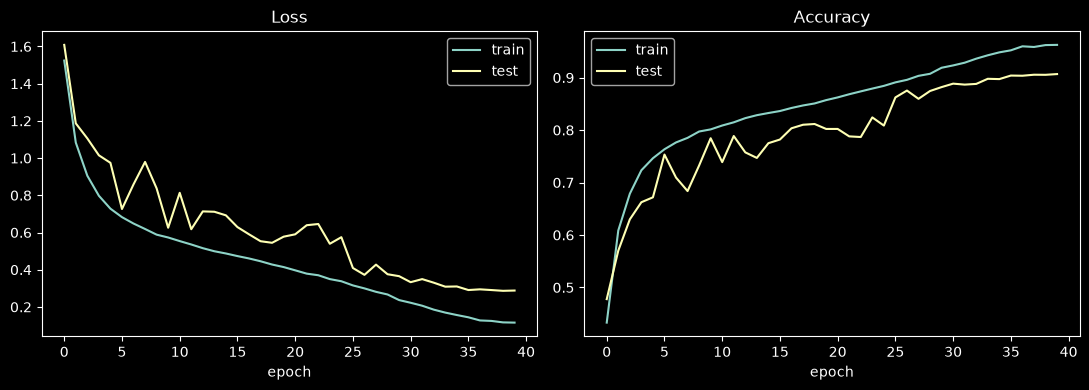

In [8]:
import matplotlib.pyplot as plt

h = histories[SEEDS[0]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(h["train_loss"], label="train")
axes[0].plot(h["test_loss"], label="test")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h["train_acc"], label="train")
axes[1].plot(h["test_acc"], label="test")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

## Fit the Laplace approximation (post-hoc)

`Laplace(model, "classification", subset_of_weights="last_layer", hessian_structure="kron")`
builds `N(theta_MAP, (H + prior_precision * I)^-1)` over the last layer. `la.fit` makes one
pass over the (un-augmented) training data to accumulate the Hessian, and
`optimize_prior_precision(method="marglik")` picks the prior precision by maximizing
the Laplace marginal likelihood (no validation data needed).

In [10]:
import copy

map_model = trained_models[SEEDS[0]]
map_model.eval()

# laplace-torch has a CPU/GPU device mismatch when building the Hessian,
# so run the Laplace step on a CPU copy (the last layer is only 650 params, so this is very feasible).
la_model = copy.deepcopy(map_model).cpu().eval()

t0 = time.time()
la = Laplace(
    la_model,
    "classification",
    subset_of_weights=LAPLACE_SUBSET,
    hessian_structure=HESSIAN_STRUCTURE,
)
la.fit(train_noaug_loader)
print(f"Hessian fit: {time.time() - t0:.1f}s")

t0 = time.time()
la.optimize_prior_precision(method=PRIOR_PREC_METHOD)
print(f"Prior precision tuned ({PRIOR_PREC_METHOD}): {time.time() - t0:.1f}s")
print(f"prior_precision = {la.prior_precision}")

Hessian fit: 70.9s


D:\University\Fourth Year - 2026-2027\CISC 473\CISC-473-P23\.venv\Lib\site-packages\laplace\baselaplace.py:470: UserWarning: By default `link_approx` is `probit`. Make sure to set it equals to the way you want to call `la(test_data, pred_type=..., link_approx=...)`.
  warnings.warn(


Prior precision tuned (marglik): 1.0s
prior_precision = tensor([3.1374])


## Laplace calibration metrics: ECE + NLL

Predictions are the closed-form GLM + probit predictive `la(x, pred_type="glm",
link_approx="probit")` which deterministic and uses no sampling. ECE and NLL are computed on that
distribution on the held-out **test** split. MAP metrics (plain softmax of the trained
network) are shown alongside as a reference.

In [11]:
@torch.no_grad()
def map_predict(model, loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        probs.append(F.softmax(model(x.to(DEVICE)), dim=1).cpu().numpy())
        labels.append(y.numpy())
    return np.concatenate(probs), np.concatenate(labels)


def laplace_predict(la, loader, pred_type=PRED_TYPE, link_approx=LINK_APPROX):
    probs, labels = [], []
    for x, y in loader:
        p = la(x, pred_type=pred_type, link_approx=link_approx)  # CPU, matches la_model
        probs.append(p.detach().cpu().numpy())
        labels.append(y.numpy())
    return np.concatenate(probs), np.concatenate(labels)


def compute_nll(probs, labels, eps=1e-12):
    p_true = probs[np.arange(len(labels)), labels]
    return float(-np.mean(np.log(np.clip(p_true, eps, 1.0))))


def compute_ece(probs, labels, n_bins=ECE_BINS):
    confidences = probs.max(axis=1)
    predictions = probs.argmax(axis=1)
    accuracies = (predictions == labels).astype(np.float64)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_stats = []

    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        in_bin = (confidences > lo) & (confidences <= hi)
        prop = in_bin.mean()
        if prop > 0:
            acc_in_bin = accuracies[in_bin].mean()
            conf_in_bin = confidences[in_bin].mean()
            ece += prop * abs(acc_in_bin - conf_in_bin)
            bin_stats.append((lo, hi, prop, acc_in_bin, conf_in_bin))

    return float(ece), bin_stats


# MAP reference
map_probs, map_labels = map_predict(map_model, test_loader)
map_acc = float((map_probs.argmax(1) == map_labels).mean())
map_nll = compute_nll(map_probs, map_labels)
map_ece, _ = compute_ece(map_probs, map_labels)

# Laplace
test_probs, test_labels = laplace_predict(la, test_loader)
la_acc = float((test_probs.argmax(1) == test_labels).mean())
la_nll = compute_nll(test_probs, test_labels)
la_ece, ece_bins = compute_ece(test_probs, test_labels)

print(f"MAP     test accuracy: {map_acc:.4f}  NLL: {map_nll:.4f}  ECE: {map_ece:.4f}")
print(f"Laplace test accuracy: {la_acc:.4f}  NLL: {la_nll:.4f}  ECE: {la_ece:.4f}")

MAP     test accuracy: 0.9067  NLL: 0.2881  ECE: 0.0285
Laplace test accuracy: 0.9066  NLL: 0.2753  ECE: 0.0145


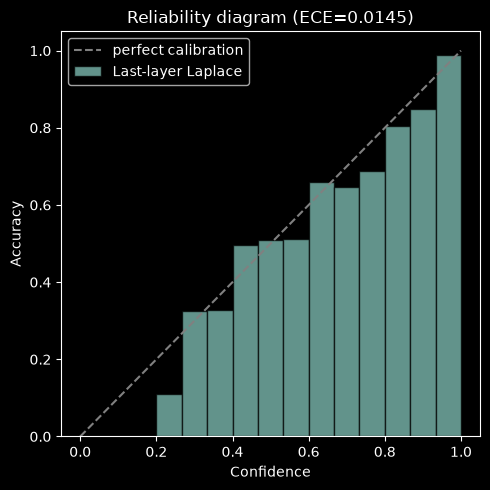

In [12]:
# Reliability diagram
confidences = test_probs.max(axis=1)
predictions = test_probs.argmax(axis=1)
accuracies = (predictions == test_labels).astype(np.float64)

bin_edges = np.linspace(0, 1, ECE_BINS + 1)
bin_centers, bin_acc = [], []
for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
    in_bin = (confidences > lo) & (confidences <= hi)
    if in_bin.sum() > 0:
        bin_centers.append((lo + hi) / 2)
        bin_acc.append(accuracies[in_bin].mean())

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
plt.bar(bin_centers, bin_acc, width=1 / ECE_BINS, alpha=0.7, edgecolor="black", label="Last-layer Laplace")
plt.xlabel("Confidence"); plt.ylabel("Accuracy")
plt.title(f"Reliability diagram (ECE={la_ece:.4f})")
plt.legend(); plt.tight_layout(); plt.show()

## Shared conformal calibration layer (split conformal, APS score)

Identical scheme to the MC Dropout / baseline notebooks where it only needs softmax
probabilities, so it wraps the Laplace predictive probabilities the same way.
Calibrated on the held-out `cal` split, evaluated on `test`.

In [13]:
def aps_scores(probs, labels):
    order = np.argsort(-probs, axis=1)
    ranked_probs = np.take_along_axis(probs, order, axis=1)
    cumsum = np.cumsum(ranked_probs, axis=1)

    true_rank = np.array([
        np.where(order[i] == labels[i])[0][0] for i in range(len(labels))
    ])
    scores = cumsum[np.arange(len(labels)), true_rank]
    return scores


def aps_predict_sets(probs, qhat):
    order = np.argsort(-probs, axis=1)
    ranked_probs = np.take_along_axis(probs, order, axis=1)
    cumsum = np.cumsum(ranked_probs, axis=1)

    pred_sets = []
    for i in range(probs.shape[0]):
        k = np.searchsorted(cumsum[i], qhat) + 1
        k = min(k, probs.shape[1])
        pred_sets.append(set(order[i, :k].tolist()))
    return pred_sets


cal_probs, cal_labels = laplace_predict(la, cal_loader)
cal_scores = aps_scores(cal_probs, cal_labels)

n_cal = len(cal_scores)
q_level = np.ceil((n_cal + 1) * (1 - ALPHA)) / n_cal
q_level = min(q_level, 1.0)
qhat = np.quantile(cal_scores, q_level, method="higher")

pred_sets = aps_predict_sets(test_probs, qhat)
covered = [test_labels[i] in pred_sets[i] for i in range(len(test_labels))]
set_sizes = [len(s) for s in pred_sets]

conformal_coverage = float(np.mean(covered))
conformal_avg_set_size = float(np.mean(set_sizes))

print(f"Target coverage        : {1 - ALPHA:.2f}")
print(f"qhat                    : {qhat:.4f}")
print(f"Empirical coverage      : {conformal_coverage:.4f}")
print(f"Average set size        : {conformal_avg_set_size:.2f}  (out of 10 classes)")

Target coverage        : 0.90
qhat                    : 0.9998
Empirical coverage      : 0.9999
Average set size        : 5.54  (out of 10 classes)


## Summary of Laplace metrics + conformal metrics

Saved to `laplace_resnet20_results.json`, in the same shape as the MC Dropout
results file (`baseline_metrics` holds this model's own metrics), so the files can be
loaded side by side later.

In [14]:
results = {
    "model": "Last-layer Laplace ResNet-20 (cifar10_resnet20 MAP + laplace-torch)",
    "reference": "Daxberger et al. 2021, https://arxiv.org/abs/2106.14806",
    "laplace": {
        "subset_of_weights": LAPLACE_SUBSET,
        "hessian_structure": HESSIAN_STRUCTURE,
        "prior_precision_method": PRIOR_PREC_METHOD,
        "prior_precision": float(la.prior_precision.mean().item()),
        "pred_type": PRED_TYPE,
        "link_approx": LINK_APPROX,
    },
    "seeds": SEEDS,
    "epochs": EPOCHS,
    "split": {"train": len(train_idx), "test": len(test_idx), "calibration": len(cal_idx)},
    "map_metrics": {
        "test_accuracy": map_acc,
        "nll": map_nll,
        "ece": map_ece,
    },
    "baseline_metrics": {
        "test_accuracy": la_acc,
        "nll": la_nll,
        "ece": la_ece,
    },
    "conformal_metrics": {
        "method": "split conformal (APS)",
        "alpha": ALPHA,
        "target_coverage": 1 - ALPHA,
        "qhat": float(qhat),
        "empirical_coverage": conformal_coverage,
        "avg_set_size": conformal_avg_set_size,
    },
}

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=2)

print(json.dumps(results, indent=2))

{
  "model": "Last-layer Laplace ResNet-20 (cifar10_resnet20 MAP + laplace-torch)",
  "reference": "Daxberger et al. 2021, https://arxiv.org/abs/2106.14806",
  "laplace": {
    "subset_of_weights": "last_layer",
    "hessian_structure": "full",
    "prior_precision_method": "marglik",
    "prior_precision": 3.1373870372772217,
    "pred_type": "glm",
    "link_approx": "probit"
  },
  "seeds": [
    0
  ],
  "epochs": 40,
  "split": {
    "train": 36000,
    "test": 12000,
    "calibration": 12000
  },
  "map_metrics": {
    "test_accuracy": 0.90675,
    "nll": 0.28806445002555847,
    "ece": 0.028516506986071673
  },
  "baseline_metrics": {
    "test_accuracy": 0.9065833333333333,
    "nll": 0.27530810236930847,
    "ece": 0.014538627417137202
  },
  "conformal_metrics": {
    "method": "split conformal (APS)",
    "alpha": 0.1,
    "target_coverage": 0.9,
    "qhat": 0.9997949004173279,
    "empirical_coverage": 0.9999166666666667,
    "avg_set_size": 5.53775
  }
}


## Save the model

In [15]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
torch.save(map_model.state_dict(), MODEL_PATH)
print(f"Saved MAP weights to {MODEL_PATH}")

Saved MAP weights to ..\models\laplace_model\laplace_resnet20_seed0.pt
